In [ ]:
# # 데이터 분석 시 봐야 할 지표

# 1. precision, accuracy recall과 같이 봐야함
# 2. F1 score
# 3. confusion matrix(오차행렬)
# 4. ROC curve/ AUC
# 5. Threshold 자체 민감도

In [1]:
from sklearn.preprocessing import LabelEncoder

def fillna(df):
    df['Age'].fillna(df['Age'].mean(), inplace= True)
    df['Cabin'].fillna('N', inplace= True)
    df['Embarked'].fillna('N', inplace= True)
    df['Fare'].fillna(0, inplace= True)

    return df

def drop_features(df):
    df.drop(['PassengerId', 'Name', 'Ticket'], axis=1, inplace=True)
    return df

def format_features(df):
    df['Cabin'] = df['Cabin'].str[:1]
    features = ['Cabin', 'Sex', 'Embarked']
    for feature in features :
        le = LabelEncoder()
        le = le.fit(df[feature])
        df[feature] = le.transform(df[feature])
    return df

def transform_features(df):
    df = fillna(df)
    df = drop_features(df)
    df = format_features(df)
    return df

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('./train.csv')
y_df = df['Survived']
X_df = df.drop('Survived', axis=1)
X_df = transform_features(X_df)

# X_df(독립변수), y_df(타겟) 전체 데이터를 학습용 80% / 테스트용 20%로 분리
# random_state를 고정해서 매번 실행해도 동일하게 분리되도록 함
X_train, X_test, y_train, y_test = train_test_split(X_df, y_df,
                                test_size=0.2, random_state= 42)

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression

# 로지스틱 회귀 모델 생성 (liblinear: 작은 데이터셋에 적합한 최적화 알고리즘)
lr_clf = LogisticRegression(solver= 'liblinear')

# 학습용 데이터(X_train, y_train)로 모델 학습
lr_clf.fit(X_train, y_train)
# 학습된 모델로 테스트 데이터(X_test)의 생존 여부 예측
pred = lr_clf.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix # confusion_matrix - 혼동 행렬 

# 혼동 행렬: 실제값(y_test)과 예측값(pred)을 TN/FP/FN/TP 4가지로 분류해서 보여줌
confusion = confusion_matrix(y_test, pred)
# 정확도: 전체 중 맞게 예측한 비율
accuracy = accuracy_score(y_test, pred)
# 정밀도: 생존(1)으로 예측한 것 중 실제로 생존한 비율
precision = precision_score(y_test, pred)
# 재현율: 실제 생존자(1) 중 생존으로 올바르게 예측한 비율
recall = recall_score(y_test, pred)


print(confusion)
print(accuracy)
print(precision)
print(recall)

In [7]:
pred_proba = lr_clf.predict_proba(X_test)

print('pred_proba() 결과 shape:', pred_proba.shape)
print('pred_proba array 앞 3개의 샘플 : ', pred_proba[:3])

pred_proba_resul = np.concatenate([pred_proba, pred.reshape(-1, 1)], axis=1)

print('두개의 클래스 중에서 더 큰 확률을 클래스 값으로 예측 :', pred_proba_resul[:3])

pred_proba() 결과 shape: (179, 2)
pred_proba array 앞 3개의 샘플 :  [[0.88326759 0.11673241]
 [0.79435838 0.20564162]
 [0.8518596  0.1481404 ]]
두개의 클래스 중에서 더 큰 확률을 클래스 값으로 예측 : [[0.88326759 0.11673241 0.        ]
 [0.79435838 0.20564162 0.        ]
 [0.8518596  0.1481404  0.        ]]


In [ ]:
from sklearn.preprocessing import Binarizer

X = [[1, -1, 2],
     [2, 0, 0],
     [0, 1.1, 1.2]]

binarizer = Binarizer(threshold= 1.1) # threshold = 기준값  1.1보다 크면 1 아니면 0
print(binarizer.fit_transform(X))

[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]]


In [13]:
custom_threshold = 0.6

pred_proba_1 = pred_proba[:, 1].reshape(-1, 1)
binarizer = Binarizer(threshold=custom_threshold).fit(pred_proba_1)
custom_pred = binarizer.transform(pred_proba_1)

confusion = confusion_matrix(y_test, custom_pred)
accuracy = accuracy_score(y_test, custom_pred)
precision = precision_score(y_test, custom_pred)
recall = recall_score(y_test, custom_pred)

print(confusion)
print(accuracy)
print(precision)
print(recall)


[[94 11]
 [24 50]]
0.8044692737430168
0.819672131147541
0.6756756756756757


In [16]:
from sklearn.metrics import precision_recall_curve

pred_proba_class1 = lr_clf.predict_proba(X_test)[:,1]

precisions, recalls, thresholds = precision_recall_curve(y_test, pred_proba_class1)

print('반환된 분류 결정 임계값 배열의 모양 :', thresholds.shape)
print('반환된 분류 결정 정밀도 배열의 모양 :', precisions.shape)
print('반환된 분류 결정 재현율 배열의 모양 :', recalls.shape)

print('Thresholds 5 sample :', thresholds[:5])
print('precisions 5 sample :', precisions[:5])
print('recalls 5 sample :', recalls[:5])

thr_index = np.arange(0, thresholds.shape[0], 15)
print('샘플 추출을 위한 임계값 배열의 인덱스 10개 :', thr_index)
print('샘플용 10개의 임계값 :', np.round(thresholds[thr_index],2))

print('샘플 임계값 별 정밀도 :', np.round(precisions[thr_index],3))
print('샘플 임계값 별 재현율 :', np.round(recalls[thr_index],3))

반환된 분류 결정 임계값 배열의 모양 : (168,)
반환된 분류 결정 정밀도 배열의 모양 : (169,)
반환된 분류 결정 재현율 배열의 모양 : (169,)
Thresholds 5 sample : [0.09375626 0.09553834 0.09735065 0.09824914 0.09898309]
precisions 5 sample : [0.42774566 0.4244186  0.42690058 0.42941176 0.43195266]
recalls 5 sample : [1.         0.98648649 0.98648649 0.98648649 0.98648649]
샘플 추출을 위한 임계값 배열의 인덱스 10개 : [  0  15  30  45  60  75  90 105 120 135 150 165]
샘플용 10개의 임계값 : [0.09 0.12 0.14 0.15 0.2  0.29 0.36 0.57 0.66 0.73 0.87 0.93]
샘플 임계값 별 정밀도 : [0.428 0.452 0.504 0.565 0.615 0.691 0.734 0.797 0.917 1.    1.    1.   ]
샘플 임계값 별 재현율 : [1.    0.959 0.946 0.946 0.905 0.878 0.784 0.689 0.595 0.446 0.243 0.041]


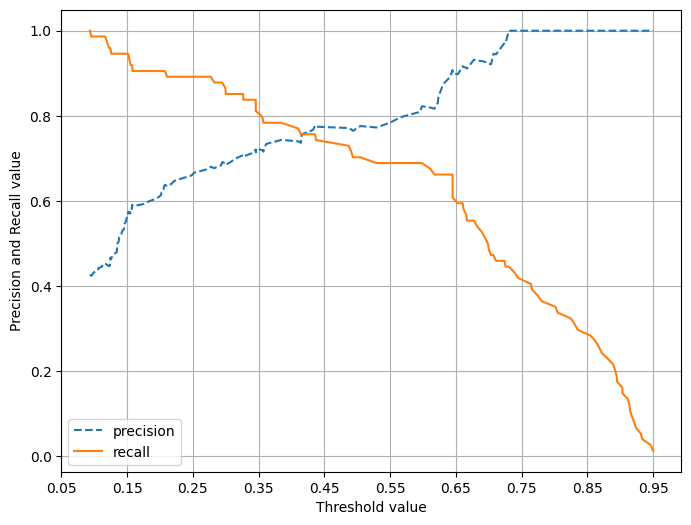

In [19]:
import matplotlib.pyplot as plt

def precision_recall_curve_plot(y_test, pred_proba_c1):
    precisions, recalls, thresholds = precision_recall_curve(y_test, pred_proba_c1)

    plt.figure(figsize=(8, 6))
    threshold_boundary = thresholds.shape[0]
    plt.plot(thresholds, precisions[0:threshold_boundary],
             linestyle='--', label='precision')
    plt.plot(thresholds, recalls[0:threshold_boundary], label='recall')

    start, end = plt.xlim()
    plt.xticks(np.round(np.arange(start, end, 0.1), 2))
    plt.xlabel('Threshold value')
    plt.ylabel('Precision and Recall value')
    plt.legend()
    plt.grid()
    plt.show()

precision_recall_curve_plot(y_test, lr_clf.predict_proba(X_test)[:, 1])

In [20]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, pred)
print(f1)

0.7375886524822697


In [22]:
from sklearn.metrics import roc_curve

pred_proba_class1 = lr_clf.predict_proba(X_test)[:,1]

# FPR = 1 - 특이도
# TPR = RECALL

fprs, tprs, thresholds = roc_curve(y_test, pred_proba_class1)
thr_index = np.arange(1, thresholds.shape[0], 5)
print(np.round(fprs[thr_index], 3))
print(np.round(tprs[thr_index], 3))

[0.    0.019 0.048 0.143 0.19  0.248 0.295 0.486 0.695 0.838]
[0.014 0.473 0.595 0.689 0.784 0.838 0.892 0.919 0.946 0.986]


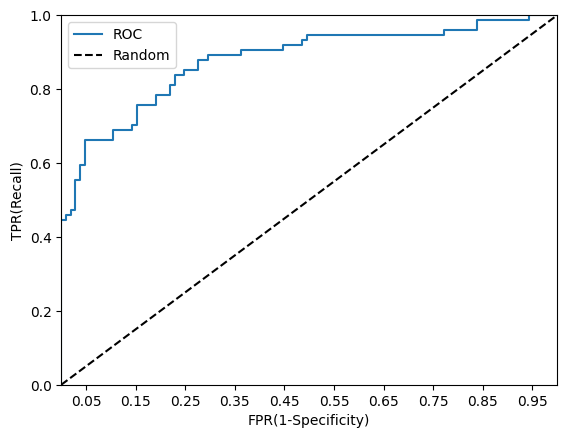

In [ ]:
def roc_curve_plot(y_test, pred_proba_c1):
    fprs, tprs, thresholds = roc_curve(y_test, pred_proba_c1)
    plt.plot(fprs, tprs, label = 'ROC')
    plt.plot([0,1], [0,1], 'k--', label = 'Random')
    start, end = plt.xlim()
    plt.xticks(np.round(np.arange(start, end, 0.1), 2))
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel('FPR(1-Specificity)')
    plt.ylabel('TPR(Recall)')
    plt.legend()
    plt.show()

roc_curve_plot(y_test, lr_clf.predict_proba(X_test)[:, 1]) # roc_curve 아래 면적 = auc score

In [ ]:
from sklearn.metrics import roc_auc_score

# pred_proba = lr_clf.predict_proba(X_test)[:, 1] pred_proba 공식

roc_score = roc_auc_score(y_test, lr_clf.predict_proba(X_test)[:, 1])
print(roc_score)

0.8774774774774776
